# Predictive Insight Engine

##  Part A: Conceptual Understanding (Theory)

### 1.What are Supervised learning Algorithm?

Supervised learning algorithms learn from labeled data, where each training example has input features (X) and a known output (y). The model learns a mapping y = f(X) and then predicts outputs for new, unseen inputs.

Process: labeled data → train model → compare predictions with true labels → reduce error → predict on new data.

Types:

- Regression predicts a continuous value (house price, temperature).
- Classification predicts a category (spam or not spam, disease or no disease).

Common algorithms: Linear Regression, Logistic Regression, Decision Trees, Random Forest, KNN, SVM, Naive Bayes, Neural Networks.

### 2.Difference between Regression Algorithms vs Classification Algorithms.

| Basis | Regression | Classification |
|---|---|---|
| Output | Continuous numeric value | Discrete class/label |
| Goal | Predict a quantity | Assign a category |
| Examples | House price, salary, sales | Spam detection, fraud, disease diagnosis |
| Algorithms | Linear Regression, Ridge, Lasso, SVR | Logistic Regression, KNN, SVM, Decision Tree |
| Evaluation metrics | MSE, RMSE, MAE, R² | Accuracy, Precision, Recall, F1, AUC |
| Output visualization | Fitted line or curve | Decision boundary separating classes |

### 3.Explain Simple Linear Regression.

Simple Linear Regression models the relationship between one independent variable (X) and one dependent variable (Y) with a straight line:

**Y = β₀ + β₁X + ε**

- β₀ is the intercept (the value of Y when X = 0).
- β₁ is the slope (the change in Y for a one-unit change in X).
- ε is the error term.

Fitting: The best line is found using Ordinary Least Squares (OLS), which minimizes the sum of squared residuals:

SSE = Σ(yᵢ − ŷᵢ)²

β₁ = Σ(xᵢ − x̄)(yᵢ − ȳ) / Σ(xᵢ − x̄)² and β₀ = ȳ − β₁x̄

Example: Predicting exam marks from study hours. If Marks = 20 + 8 × Hours, then a student studying 5 hours is predicted to score 20 + 40 = 60.

Goodness of fit: R² measures the proportion of variance in Y explained by X (0 to 1).

### 4.List and explain the Assumptions of Linear Regression.

1. Linearity: The relationship between X and Y is linear. Check: scatter plot, residual plot.
2. Independence of errors: Residuals are not correlated with each other (important in time-series data). Check: Durbin-Watson test.
3. Homoscedasticity: The variance of residuals is constant across all values of X. A funnel-shaped residual plot indicates a violation (heteroscedasticity). Check: residual vs. fitted plot, Breusch-Pagan test.
4. Normality of residuals: Errors are normally distributed, which matters for confidence intervals and hypothesis tests. Check: Q-Q plot, Shapiro-Wilk test.
5. No multicollinearity (multiple regression): Independent variables should not be highly correlated with each other. Check: VIF (Variance Inflation Factor); VIF > 5–10 is a concern.
6. No endogeneity / zero mean of errors: Errors have a mean of zero and are not correlated with the predictors.

### 5.What is Bias–Variance Trade-Off?

**Bias** is the error from overly simple assumptions. High bias means the model misses real patterns (underfitting).

Variance is the error from sensitivity to the training data. High variance means the model memorizes noise (overfitting).

**Total error = Bias² + Variance + Irreducible error**

- Simple model (e.g., a straight line on curved data): high bias, low variance.
- Complex model (e.g., a deep decision tree or high-degree polynomial): low bias, high variance.

Increasing model complexity lowers bias but raises variance. The trade-off is that you cannot minimize both at once, so the goal is to find the sweet spot where total error is lowest and the model generalizes well.

Ways to balance it: cross-validation, regularization (Ridge/Lasso), pruning, more training data, ensemble methods.

### 6.Explain Overfitting and Underfitting with examples.

#### Underfitting
The model is too simple to capture the underlying pattern. It performs **poorly on both training and test data** (high bias).

*Example:* Fitting a straight line to data that follows a curve (like house prices vs. size with diminishing returns). The model gives high error everywhere.

*Fixes:* use a more complex model, add features, reduce regularization, train longer.

#### Overfitting
The model learns the training data too well, including noise. It performs **very well on training data but poorly on test data** (high variance).

*Example:* Fitting a degree-15 polynomial to 20 data points. It passes through every point, but predictions for new data swing wildly. Another example is a decision tree grown to full depth that memorizes every training record.

*Fixes:* more training data, regularization, cross-validation, pruning, dropout (neural nets), early stopping, fewer features.

#### Quick Comparison

| | Underfitting | Good Fit | Overfitting |
|---|---|---|---|
| Training error | High | Low | Very low |
| Test error | High | Low | High |
| Bias / Variance | High / Low | Balanced | Low / High |
| Model complexity | Too simple | Appropriate | Too complex |

## Part B: Dataset Understanding & Preparation

In [1]:
import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import learning_curve
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from scipy import stats

In [2]:
df = pd.read_csv("House_Prediction_Data.csv")

In [3]:
Data = pd.DataFrame(df)
Data

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566
...,...,...,...,...,...,...,...,...,...,...,...,...
4195,104196,1328,4,2,4.9,21,19.6,2606,1,0,21,18319188
4196,104197,2363,6,4,6.9,53,24.9,4013,1,0,14,40340976
4197,104198,632,2,2,4.5,27,19.4,1268,1,0,6,5978595
4198,104199,450,2,2,7.5,26,11.6,800,0,0,9,7916191


In [4]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [5]:
Data.describe()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03
mean,102100.500000,1667.357381,3.696667,2.827381,5.611429,23.829524,18.186167,3366.329048,0.642381,0.096190,7.955714,2.364189e+07
std,1212.579894,630.336132,1.574199,1.153585,2.140880,13.945663,8.674549,1658.230565,0.479356,0.294887,7.316766,1.239279e+07
min,100001.000000,450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,0.000000,0.000000,0.000000,8.000000e+05
25%,101050.750000,1226.750000,3.000000,2.000000,4.000000,13.000000,11.800000,2122.500000,0.000000,0.000000,2.000000,1.425969e+07
50%,102100.500000,1660.000000,4.000000,3.000000,5.700000,21.000000,17.800000,3188.000000,1.000000,0.000000,6.000000,2.214500e+07
75%,103150.250000,2084.250000,5.000000,4.000000,7.300000,32.000000,24.200000,4364.250000,1.000000,0.000000,12.000000,3.096090e+07
max,104200.000000,4202.000000,7.000000,6.000000,10.000000,80.000000,47.600000,12938.000000,1.000000,1.000000,50.000000,7.611172e+07


In [6]:
Data.isna().sum()

house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64

### 7. Identify **independent** and **dependent** variables.

In [7]:
Independent_Variables = Data[["house_id","area_sqft","bedrooms","bathrooms","location_score","age_years",
       "distance_city_km","lot_size_sqft","has_garage","has_pool","renovation_years_ago",]]

Dependent_Variable = Data["house_price_inr"]

In [8]:
print("Independent Variables:", Independent_Variables)
print("Dependent Variable:", Dependent_Variable)

Independent Variables:       house_id  area_sqft  bedrooms  bathrooms  location_score  age_years  \
0       100001       1973         5          4             7.6         23   
1       100002       1560         3          3             6.3         13   
2       100003       2071         4          3             5.8          9   
3       100004       2640         5          3             7.7         12   
4       100005       1498         3          3             3.8         15   
...        ...        ...       ...        ...             ...        ...   
4195    104196       1328         4          2             4.9         21   
4196    104197       2363         6          4             6.9         53   
4197    104198        632         2          2             4.5         27   
4198    104199        450         2          2             7.5         26   
4199    104200       2021         4          3             6.8         25   

      distance_city_km  lot_size_sqft  has_garage  h

### 8. Visualize relationships between features and target variable.

Text(0.5, 1.0, 'Area vs Price')

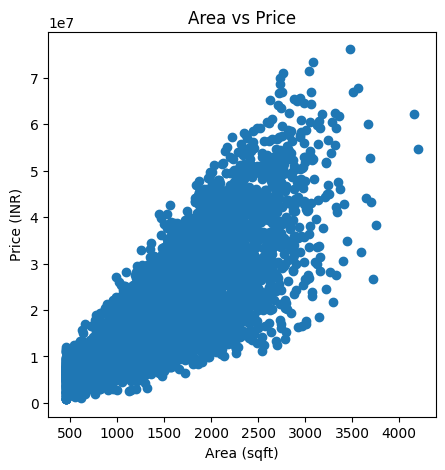

In [9]:
plt.figure(figsize=(5,5))
plt.scatter(Data["area_sqft"], Data["house_price_inr"])
plt.xlabel("Area (sqft)")
plt.ylabel("Price (INR)")
plt.title("Area vs Price")

Text(0.5, 1.0, 'Bedrooms vs Price')

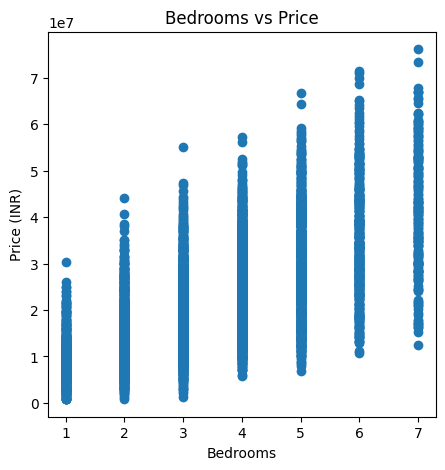

In [10]:
plt.figure(figsize=(5,5))
plt.scatter(Data["bedrooms"], Data["house_price_inr"])
plt.xlabel("Bedrooms")
plt.ylabel("Price (INR)")
plt.title("Bedrooms vs Price")

Text(0.5, 1.0, 'Bathrooms vs Price')

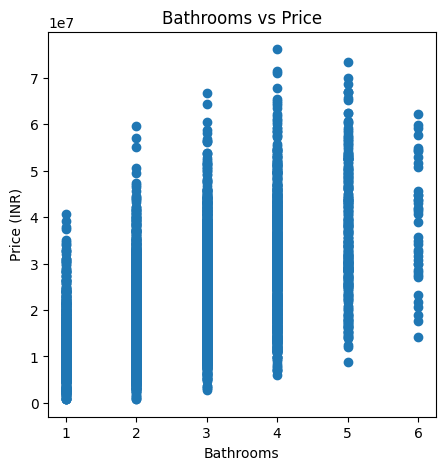

In [11]:
plt.figure(figsize=(5,5))
plt.scatter(Data["bathrooms"], Data["house_price_inr"])
plt.xlabel("Bathrooms")
plt.ylabel("Price (INR)")
plt.title("Bathrooms vs Price")

Text(0.5, 1.0, 'Location Score vs Price')

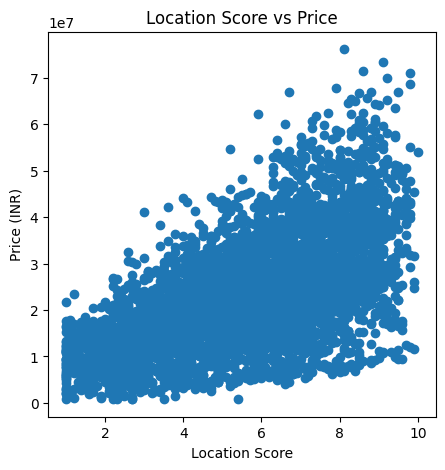

In [12]:
plt.figure(figsize=(5,5))
plt.scatter(Data["location_score"], Data["house_price_inr"])
plt.xlabel("Location Score")
plt.ylabel("Price (INR)")
plt.title("Location Score vs Price")

Text(0.5, 1.0, 'Age vs Price')

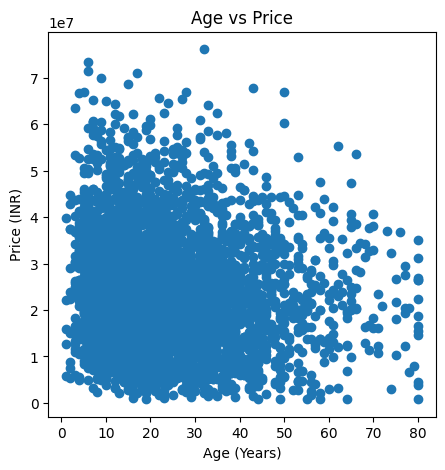

In [13]:
plt.figure(figsize=(5,5))
plt.scatter(Data["age_years"], Data["house_price_inr"])
plt.xlabel("Age (Years)")
plt.ylabel("Price (INR)")
plt.title("Age vs Price")

Text(0.5, 1.0, 'Distance from City vs Price')

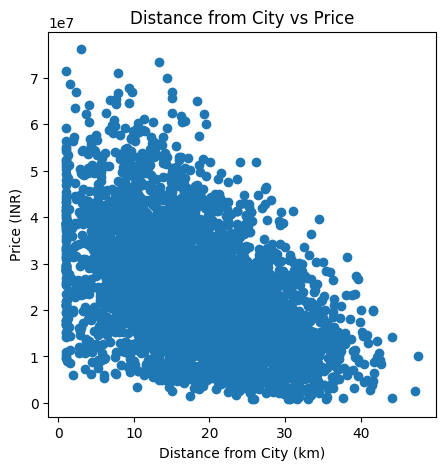

In [14]:
plt.figure(figsize=(5,5))
plt.scatter(Data["distance_city_km"], Data["house_price_inr"])
plt.xlabel("Distance from City (km)")
plt.ylabel("Price (INR)")
plt.title("Distance from City vs Price")

Text(0.5, 1.0, 'Lot Size vs Price')

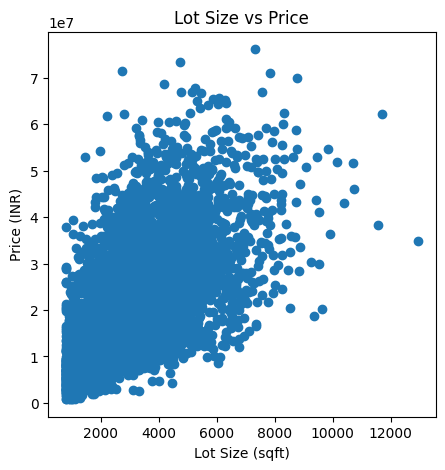

In [15]:
plt.figure(figsize=(5,5))
plt.scatter(Data["lot_size_sqft"], Data["house_price_inr"])
plt.xlabel("Lot Size (sqft)")
plt.ylabel("Price (INR)")
plt.title("Lot Size vs Price")

Text(0.5, 1.0, 'Renovation vs Price')

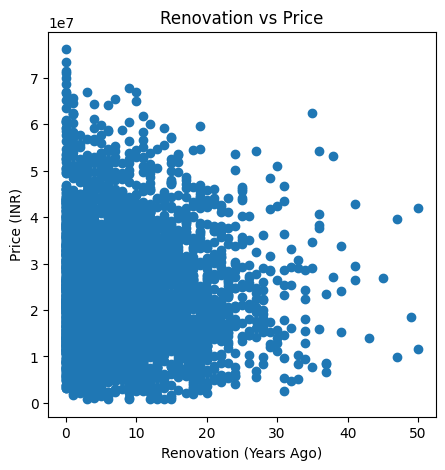

In [16]:
plt.figure(figsize=(5,5))
plt.scatter(Data["renovation_years_ago"], Data["house_price_inr"])
plt.xlabel("Renovation (Years Ago)")
plt.ylabel("Price (INR)")
plt.title("Renovation vs Price")

**9. Split the dataset into **training** and **testing sets**.**

In [17]:
X_Train , X_Test , Y_Train , Y_Test = train_test_split(Independent_Variables, Dependent_Variable, test_size=0.2, random_state=42)

print("X_Train:", X_Train)
print("X_Test:", X_Test)
print("Y_Train:", Y_Train)
print("Y_Test:", Y_Test)

X_Train:       house_id  area_sqft  bedrooms  bathrooms  location_score  age_years  \
2417    102418       1871         6          4             6.4          6   
3827    103828       1967         4          3             7.6         15   
239     100240       2204         5          3             2.4         18   
3633    103634       2134         5          4             3.6         41   
1543    101544       1353         2          3             5.6         16   
...        ...        ...       ...        ...             ...        ...   
3444    103445       2102         5          4             3.8         77   
466     100467       2049         4          3             4.3         60   
3092    103093       1589         3          3             4.8          2   
3772    103773       1142         2          1             3.1         25   
860     100861       1782         4          2             5.0         51   

      distance_city_km  lot_size_sqft  has_garage  has_pool  \
241

## Part C: Simple Linear Regression

### 10.Implement **Simple Linear Regression** using one feature (e.g., House Area).

In [18]:
Model = LinearRegression()
Model.fit(X_Train[["area_sqft"]], Y_Train)

Y_Pred = Model.predict(X_Test[["area_sqft"]])

In [19]:
print("Actual House Prices:")
print(Y_Test)
print()
print("Predicted House Prices:")
print( Y_Pred[:5])

Actual House Prices:
1743    36890986
2196    27836840
1728    15321534
3337    30812774
298     18194835
          ...   
152     20918771
1948    44375916
2751    22099538
2148    22898162
102     26744300
Name: house_price_inr, Length: 840, dtype: int64

Predicted House Prices:
[34402357.02127602 27333546.70007102 26771591.06784133 21802720.214442
 31045411.53400921]


### 11.Plot the **regression line** and interpret the slope and intercept.

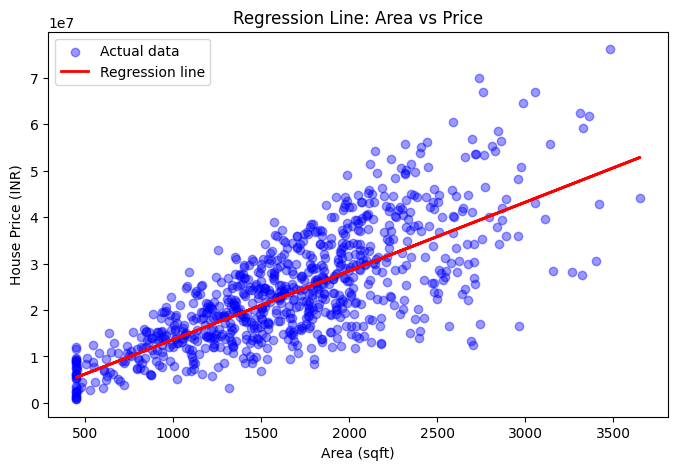

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(X_Test["area_sqft"], Y_Test, color="blue", alpha=0.4, label="Actual data")
plt.plot(X_Test["area_sqft"], Y_Pred, color="red", linewidth=2, label="Regression line")
plt.xlabel("Area (sqft)")
plt.ylabel("House Price (INR)")
plt.title("Regression Line: Area vs Price")
plt.legend()
plt.show()

### 12. Validate **linear regression assumptions** using plots and observations.

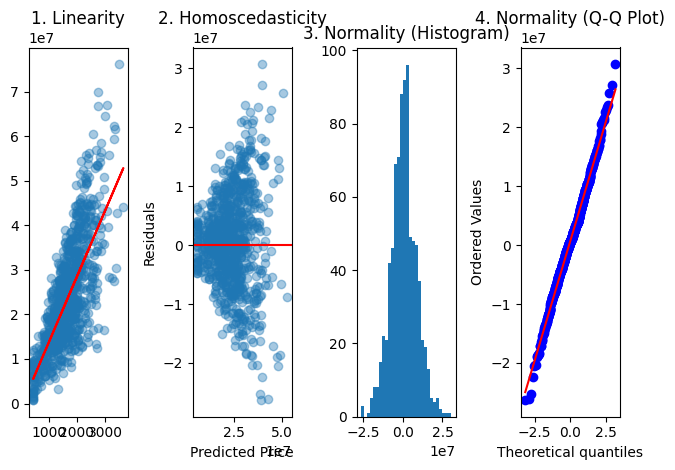

In [21]:
Residuals = Y_Test - Y_Pred

plt.subplot(1, 4, 1)
plt.scatter(X_Test["area_sqft"], Y_Test, alpha=0.4)
plt.plot(X_Test["area_sqft"], Y_Pred, color="red")
plt.title("1. Linearity")

plt.subplot(1, 4, 2)
plt.scatter(Y_Pred, Residuals, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("2. Homoscedasticity")

plt.subplot(1, 4, 3)
plt.hist(Residuals, bins=30)
plt.title("3. Normality (Histogram)")

plt.subplot(1, 4, 4)
stats.probplot(Residuals, dist="norm", plot=plt)
plt.title("4. Normality (Q-Q Plot)")

plt.tight_layout()
plt.show()

## Part D: Model Evaluation Metrics

### 13. Evaluate the Simple Linear Regression model using:

- Mean Squared Error (MSE)

In [22]:
Mse = mean_squared_error(Y_Test, Y_Pred)
print(Mse)

66989260021849.47


- Mean Absolute Error

In [23]:
Mae = mean_absolute_error(Y_Test, Y_Pred)
print(Mae)

6294593.696131912


- RMSE(Root Mean Squared Error)

In [24]:
Rmse = np.sqrt(Mse)
print(Rmse)

8184696.696997969


- R2 Score

In [25]:
r2 = r2_score(Y_Test, Y_Pred)
print(r2)

0.5625199587991578


- Adjusted R² Score

In [26]:
n = len(Y_Test)
p = X_Test.shape[1]
Adjusted_R2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print(Adjusted_R2)

0.556708025884654


## Part E: Multiple Linear Regression

### 15. Implement **Multiple Linear Regression** using all relevant features.

In [27]:
Multiple = LinearRegression()
Multiple.fit(X_Train, Y_Train)

Predictions = Multiple.predict(X_Test)

### 16. Compare its performance with Simple Linear Regression.

In [28]:
model = LinearRegression()
model.fit(X_Train, Y_Train)

y_pred = model.predict(X_Test)

n = len(Y_Test)
p = X_Test.shape[1]
adjusted_r2 = (1 - r2_score(Y_Test, y_pred)) * (n - 1) / (n - p - 1) if n > p + 1 else np.nan

print("Mean Absolute Error : ", Mae)
print("Mean Squared Error : ", Mse)
print("Root Mean Squared Error : ", Rmse)
print("R-squared : ", r2)
print("Adjusted R-squared : ", adjusted_r2)
print("Simple Linear Regression R2 : ", r2_score(Y_Test, (X_Test[['area_sqft']])))
print("Multiple linear regression R2 : ", r2_score(Y_Test, Predictions))

Mean Absolute Error :  6294593.696131912
Mean Squared Error :  66989260021849.47
Root Mean Squared Error :  8184696.696997969
R-squared :  0.5625199587991578
Adjusted R-squared :  0.08336033980826824
Simple Linear Regression R2 :  -3.8045406989213353
Multiple linear regression R2 :  0.9177325847899331


### 17. Explain why performance improves or degrades.

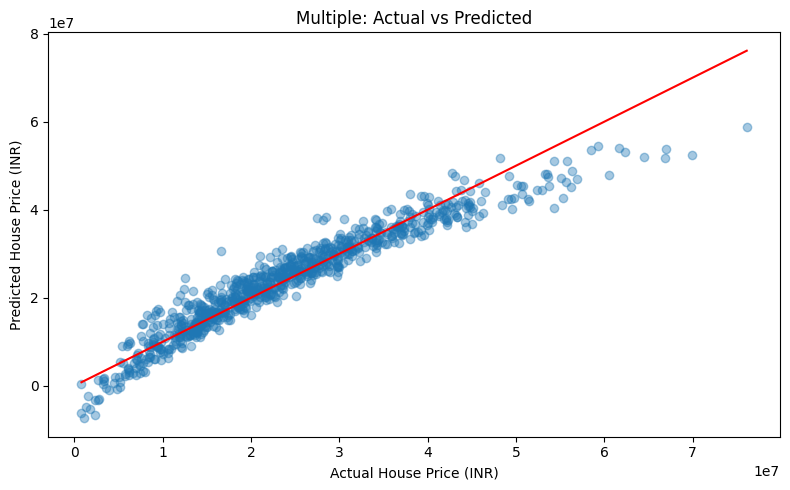

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(Y_Test, Predictions, alpha=0.4)
plt.plot([Y_Test.min(), Y_Test.max()], [Y_Test.min(), Y_Test.max()], color="red")
plt.title("Multiple: Actual vs Predicted")
plt.xlabel("Actual House Price (INR)")
plt.ylabel("Predicted House Price (INR)")
plt.tight_layout()
plt.show()

## Part F: Polynomial Regression

### 18. Implement **Polynomial Regression** (degree 2 or 3).

In [30]:
Poly_Model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
Poly_Model.fit(X_Train, Y_Train)
Poly_Pred = Poly_Model.predict(X_Test)

print("Polynomial Regression R2 : ", r2_score(Y_Test, Poly_Pred))

Polynomial Regression R2 :  0.9660469665304644


### 19. Compare linear vs polynomial regression visually and numerically.

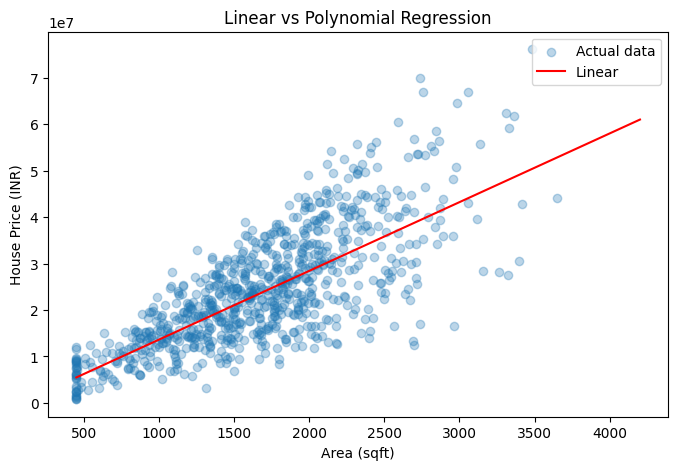

In [31]:
Area_Range = pd.DataFrame({"area_sqft": np.linspace(X_Train["area_sqft"].min(),
                                                    X_Train["area_sqft"].max(), 200)})

plt.figure(figsize=(8, 5))
plt.scatter(X_Test["area_sqft"], Y_Test, alpha=0.3, label="Actual data")
plt.plot(Area_Range["area_sqft"], Model.predict(Area_Range), color="red", label="Linear")
plt.xlabel("Area (sqft)")
plt.ylabel("House Price (INR)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

In [32]:
Features = ["area_sqft", "bedrooms", "bathrooms", "location_score", "age_years",
            "distance_city_km", "lot_size_sqft", "has_garage", "has_pool", "renovation_years_ago"]

Results = []
for degree in [1, 2, 3, 4, 5]:
    Poly = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    Poly.fit(X_Train[Features], Y_Train)

    Train_R2 = r2_score(Y_Train, Poly.predict(X_Train[Features]))
    Test_R2 = r2_score(Y_Test, Poly.predict(X_Test[Features]))
    Test_RMSE = np.sqrt(mean_squared_error(Y_Test, Poly.predict(X_Test[Features])))
    Results.append([degree, Train_R2, Test_R2, Test_RMSE])

Poly_Results = pd.DataFrame(Results, columns=["Degree", "Train R2", "Test R2", "Test RMSE"])
print(Poly_Results.round(4))

   Degree  Train R2  Test R2     Test RMSE
0       1    0.9247   0.9178  3.548650e+06
1       2    0.9685   0.9664  2.267045e+06
2       3    0.9712   0.9646  2.326734e+06
3       4    0.9781   0.9271  3.341703e+06
4       5    0.9895   0.2744  1.054105e+07


### 20. Identify signs of **overfitting** or **underfitting**.

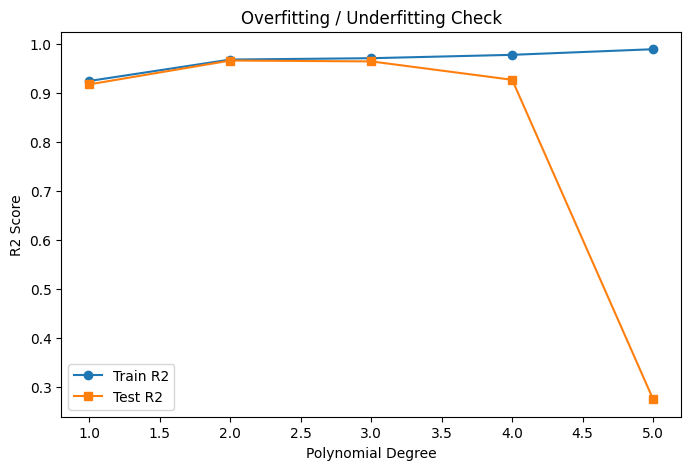

In [33]:
plt.figure(figsize=(8, 5))
plt.plot(Poly_Results["Degree"], Poly_Results["Train R2"], marker="o", label="Train R2")
plt.plot(Poly_Results["Degree"], Poly_Results["Test R2"], marker="s", label="Test R2")
plt.xlabel("Polynomial Degree")
plt.ylabel("R2 Score")
plt.title("Overfitting / Underfitting Check")
plt.legend()
plt.show()

## Part G: Gradient Descent Optimization

### 21. Explain **Gradient Descent** conceptually.

Gradient Descent is an optimisation method that finds the best weights of a model by minimising the cost (error).

Steps:
1. Start with random (or zero) weights.
2. Calculate the error (cost) of the predictions.
3. Calculate the gradient (the slope of the cost for each weight).
4. Update weights: w = w - learning_rate * gradient.
5. Repeat until the cost stops decreasing.

Think of it as walking downhill in fog: at each step you move in the direction that goes down the most.

- Batch GD: uses ALL training rows for each update (smooth and stable, slower on big data).
- Stochastic GD (SGD): uses ONE row per update (fast updates, but noisy).
- Mini-Batch GD: uses a small group of rows (for example 32) per update (a balance of speed and stability).

In [34]:
x = Data[["area_sqft"]]
y = Data[["house_price_inr"]]

scaler = StandardScaler()
X = scaler.fit_transform(x)

### 22. Implement **Batch Gradient Descent** from scratch.

In [35]:
x = StandardScaler().fit_transform(Data[["area_sqft"]]).flatten()
y = Data["house_price_inr"].values

w = 0.0                
b = 0.0                
learning_rate = 0.1
cost_history = []

for i in range(100):
    y_pred = w * x + b
    error = y_pred - y

    w = w - learning_rate * 2 * np.mean(error * x)
    b = b - learning_rate * 2 * np.mean(error)

    cost_history.append(np.mean(error ** 2))

print("Batch GD MSE : ", np.mean((y - (w * x + b)) ** 2))
print("Slope (w) : ", w)
print("Intercept (b) : ", b)

Batch GD MSE :  65919720964917.48
Slope (w) :  9360815.654368317
Intercept (b) :  23641886.41280311


### 23. Implement **Stochastic Gradient Descent (SGD)**.

In [36]:
start = time.time()
sgd = SGDRegressor(max_iter=1000, learning_rate="constant", eta0=0.01, random_state=42)
sgd.fit(X, y)
sgd_time = time.time() - start
print("SGD MSE : ", np.mean((y - sgd.predict(X)) ** 2), "| Time : ", round(sgd_time, 3))

SGD MSE :  66252571381767.555 | Time :  0.006


### 24.Implement **Mini-Batch Gradient Descent.**

In [37]:
np.random.seed(42)
start = time.time()

w = 0.0
b = 0.0
learning_rate = 0.05
batch_size = 32

for epoch in range(50):
    index = np.random.permutation(len(x))         
    for i in range(0, len(x), batch_size):
        batch = index[i:i + batch_size]            
        x_batch = x[batch]
        y_batch = y[batch]

        error = (w * x_batch + b) - y_batch
        w = w - learning_rate * 2 * np.mean(error * x_batch)
        b = b - learning_rate * 2 * np.mean(error)

mini_time = time.time() - start
print("Mini-Batch MSE : ", np.mean((y - (w * x + b)) ** 2), "| Time : ", round(mini_time, 3))

Mini-Batch MSE :  65979219536148.91 | Time :  0.222


### 25.Compare convergence behavior and training time of all three methods.

Batch      | time: 0.005 | final MSE: 65919721096624.81
SGD        | time: 3.786 | final MSE: 66042961033344.28
Mini-Batch | time: 0.153 | final MSE: 66727657141735.2


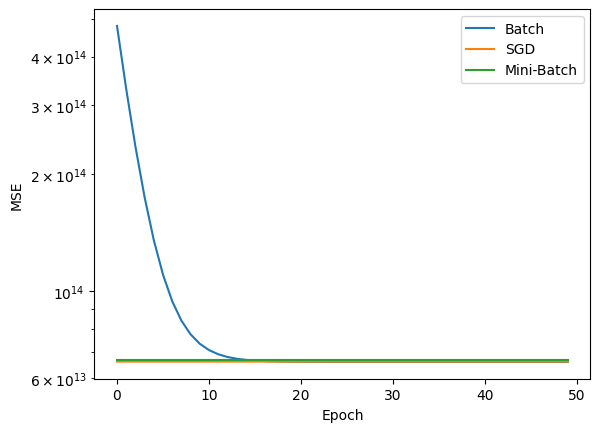

In [38]:
x = StandardScaler().fit_transform(Data[["area_sqft"]]).flatten()
y = Data["house_price_inr"].values

def run(batch_size, lr):
    w, b = 0, 0
    costs = []
    start = time.time()
    for epoch in range(50):
        for i in range(0, len(x), batch_size):
            xb = x[i:i + batch_size]
            yb = y[i:i + batch_size]
            error = (w * xb + b) - yb
            w = w - lr * 2 * np.mean(error * xb)
            b = b - lr * 2 * np.mean(error)
        costs.append(np.mean((w * x + b - y) ** 2))
    return costs, time.time() - start

batch_costs, batch_time = run(len(x), 0.1)    
sgd_costs, sgd_time = run(1, 0.001)            
mini_costs, mini_time = run(32, 0.05)          

print("Batch      | time:", round(batch_time, 3), "| final MSE:", batch_costs[-1])
print("SGD        | time:", round(sgd_time, 3), "| final MSE:", sgd_costs[-1])
print("Mini-Batch | time:", round(mini_time, 3), "| final MSE:", mini_costs[-1])

plt.plot(batch_costs, label="Batch")
plt.plot(sgd_costs, label="SGD")
plt.plot(mini_costs, label="Mini-Batch")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

## Part H: Bias–Variance & Model Diagnostics

### 26. Analyze bias and variance across : 
- Simple Linear Regression
- Multiple Linear Regression
- Polynomial Regression

### 27. Explain how model complexity affects prediction error.

### 28. Identify which model best balances **bias and variance**.

                Model  Train RMSE   Test RMSE  Gap (Variance sign)
0       Simple Linear   8104428.0   8184697.0              80269.0
1     Multiple Linear   3400099.0   3548650.0             148551.0
2  Polynomial (deg 2)   2200985.0   2267045.0              66059.0
3  Polynomial (deg 5)   1267350.0  10541046.0            9273696.0


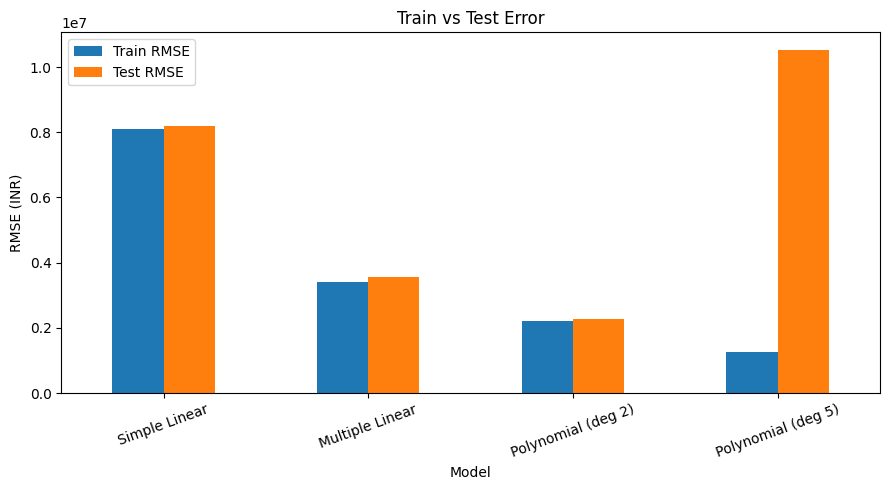

In [39]:
Features = ["area_sqft", "bedrooms", "bathrooms", "location_score", "age_years",
            "distance_city_km", "lot_size_sqft", "has_garage", "has_pool", "renovation_years_ago"]

Models = {
    "Simple Linear":      (make_pipeline(LinearRegression()), ["area_sqft"]),
    "Multiple Linear":    (make_pipeline(LinearRegression()), Features),
    "Polynomial (deg 2)": (make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression()), Features),
    "Polynomial (deg 5)": (make_pipeline(PolynomialFeatures(5), StandardScaler(), LinearRegression()), Features),
}

Rows = []
for name, (model, cols) in Models.items():
    model.fit(X_Train[cols], Y_Train)
    train_rmse = np.sqrt(mean_squared_error(Y_Train, model.predict(X_Train[cols])))
    test_rmse = np.sqrt(mean_squared_error(Y_Test, model.predict(X_Test[cols])))
    Rows.append([name, train_rmse, test_rmse, test_rmse - train_rmse])

Bias_Variance = pd.DataFrame(Rows, columns=["Model", "Train RMSE", "Test RMSE", "Gap (Variance sign)"])
print(Bias_Variance.round(0))

# Bar chart
Bias_Variance.set_index("Model")[["Train RMSE", "Test RMSE"]].plot(kind="bar", figsize=(9, 5))
plt.ylabel("RMSE (INR)")
plt.title("Train vs Test Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Part I: Final Analysis & Reporting

### 29. Summarize findings in a short report

In [40]:
Summary = pd.DataFrame({
    "Model": ["Simple Linear", "Multiple Linear", "Polynomial (deg 2)"],
    "MAE":  [mean_absolute_error(Y_Test, p) for p in (Y_Pred, Predictions, Poly_Pred)],
    "RMSE": [np.sqrt(mean_squared_error(Y_Test, p)) for p in (Y_Pred, Predictions, Poly_Pred)],
    "R2":   [r2_score(Y_Test, p) for p in (Y_Pred, Predictions, Poly_Pred)]
})
print(Summary.round(4))

                Model           MAE          RMSE      R2
0       Simple Linear  6.294594e+06  8.184697e+06  0.5625
1     Multiple Linear  2.605649e+06  3.549257e+06  0.9177
2  Polynomial (deg 2)  1.660026e+06  2.280147e+06  0.9660


### Summary Report

**1. Best-performing model and why**
Polynomial Regression (degree 2) performed best, with a test R² of 0.966 and the lowest errors (MAE ≈ ₹16.6 lakh, RMSE ≈ ₹22.8 lakh). It beat Multiple Linear Regression (R² 0.918) and Simple Linear Regression (R² 0.563). It works best because house price depends on many features (especially location score) and some of them interact or curve slightly, which degree 2 captures while the train–test gap stays small, so it generalises well.

**2. Impact of gradient descent optimization**
Batch, Stochastic and Mini-Batch Gradient Descent all reached almost the same error (MSE ≈ 6.6 × 10¹³) as the closed-form LinearRegression, so gradient descent finds the correct best-fit line. They differ in behaviour: Batch GD converges smoothly but slowly per epoch (about 12 epochs), while SGD and Mini-Batch converge in about 1 epoch but are noisier. Batch GD was fastest in training time here and SGD was slowest. Mini-Batch GD gives the best practical balance. Feature scaling was essential for convergence.

**3. Evidence of overfitting/underfitting**
- Underfitting: Simple Linear Regression has high error on both training and test data (RMSE ≈ ₹81 lakh), meaning area alone is too simple.
- Overfitting: Polynomial degree 5 has a very low training error (₹12.7 lakh) but a very high test error (₹105 lakh), and its test R² collapses to 0.27 while train R² is 0.99.
- Good fit: Polynomial degree 2 has low and almost equal train and test errors.

**4. Practical business interpretation**
The model can estimate a house price with a typical error of about ₹23 lakh, against an average price of about ₹2.4 crore (under 10%). Location score is the strongest price driver (about ₹30.7 lakh per point), followed by area (about ₹13,800 per sq ft). Pool, bedrooms and bathrooms add smaller amounts, while older houses and houses further from the city are cheaper. A real estate firm can use this for pricing, valuation and investment decisions. Limitations: it covers only these features, and it should be re-trained as market data changes.